# Creating a TimesFM Forecast model

[📥 Download Notebook](https://github.com/Mosqlimate-project/mosqlimate-client/blob/main/docs/tutorials/timesfm_model.ipynb)
 
TimesFM (Time Series Foundation Model) is a pretrained machine learning model developed by Google Research for time series forecasting. Unlike traditional forecasting approaches, TimesFM is trained on large collections of time series data and can generate forecasts for new datasets without requiring additional model training or fine-tuning.

The model can be used to predict future values based on historical observations, making it suitable for a variety of forecasting tasks. It also supports the use of additional covariates, allowing users to incorporate relevant information that may improve forecasting performance.

In this tutorial, we use TimesFM to generate forecasts over a user-defined prediction horizon, without requiring a separate training stage. 

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

To download epidemiological data, provide your Mosqlimate API key:

In [2]:
import os
from dotenv import load_dotenv
load_dotenv()

api_key = os.getenv("MOSQLIMATE_API_KEY")

Import the required packages

In [3]:
import pandas as pd
from datetime import date
import mosqlient as mosq 
import matplotlib.pyplot as plt 
from mosqlient.forecast import ForecastTimesFM3
from mosqlient.forecast.viz import  plot_single_forecast

/home/eduardocorrea/miniforge3/envs/test_mosq/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Load the dataset

Retrieve historical data on dengue in Joinville (4209102) for the period from January 1, 2022, to December 31, 2024, available on Infodengue.

In [4]:
df = mosq.get_infodengue(
    api_key=api_key,
    disease="dengue",
    uf="SC",
    geocode=4209102, 
    start_date= '2022-01-01', 
    end_date = '2024-12-31'
)

df.data_iniSE = pd.to_datetime(df.data_iniSE)

df.head()

2026-11-04 19:18:48.880 | WARNING  | mosqlient.client:__fetch_temp_credentials:84 - You are using a demo version of the API. If you want a full version, please register at www.mosqlimate.org and use your own api_key.


,data_iniSE,SE,casos_est,casos_est_min,casos_est_max,casos,municipio_geocodigo,p_rt1,p_inc100k,Localidade_id,...,nivel_inc,umidmed,umidmin,tempmed,tempmax,casprov,casprov_est,casprov_est_min,casprov_est_max,casconf
0,2022-01-02,202201,104.0,104,104,104,4209102,0.990605,17.401257,0,...,1,80.816863,66.186785,25.442678,28.285714,0,None,None,None,None
1,2022-01-09,202202,132.0,132,132,132,4209102,0.999988,22.086210,0,...,1,86.548587,72.114284,24.134921,27.142857,3,None,None,None,None
2,2022-01-16,202203,117.0,117,117,117,4209102,0.928869,19.576414,0,...,1,77.022551,62.847556,28.316739,31.571429,3,None,None,None,None
3,2022-01-23,202204,76.0,76,76,76,4209102,0.003210,12.716303,0,...,1,82.991718,71.244126,25.773809,28.428571,2,None,None,None,None
4,2022-01-30,202205,62.0,62,62,62,4209102,0.000294,10.373826,0,...,1,82.772314,64.557818,26.068028,30.142857,4,None,None,None,None


### Create the model

The main parameters required to initialize the class are as follows:

* `per_core_batch_size` : Batch size used by the TimesFM evaluator during inference.
        
* `date_col`: Name of the column containing observation dates. The same name is used for the datetime index after preprocessing.

* `target_col`: Name of the column containing the target time series values
            to be forecast.

* `device`: Device used for model inference, such as "cuda" or "cpu".

In [5]:
model = ForecastTimesFM3(target_col="casos",
                          date_col = "data_iniSE", 
                          device="cuda", 
                          per_core_batch_size = 16)

Make the forecast using past-only covariates. The main parameters are: 

* `past_only_covariates`: List with covariates available only for the historical context. 
* `predict_n` : Number of future time steps to forecast.
* `look_back` : Number of most recent observations used as model context. If None,
            all available historical observations are used.


In this example, we will use "tempmin", "umidmin", and "Rt" as auxiliary covariates for forecasting, using all available historical observations of data to predict the next 4 weeks. 


Additionally, we will use data prior to 2023-12-31 to generate forecasts and compare them with the observed values.

In [22]:
df_input = df.loc[df.data_iniSE<= '2023-12-31']

df_for = model.forecast(
         df_input,
         look_back= None, 
         predict_n=4,
         past_only_covariates=["tempmin",
             "umidmin",
             "Rt"] )

df_for.head()

,date,horizon,lower_95,lower_90,lower_80,lower_50,pred,upper_50,upper_80,upper_90,upper_95
0,2024-01-07,1,272.956673,381.450860,513.000488,687.751251,841.195557,1033.420227,1498.657349,1638.367361,1759.544961
1,2024-01-14,2,123.946671,221.901536,375.557312,639.338837,899.033386,1479.443970,2325.055664,2601.383511,2841.056709
2,2024-01-21,3,69.419576,132.868512,246.104675,566.142029,980.203918,1814.527100,2986.270508,3374.669977,3711.548593
3,2024-01-28,4,39.796497,78.077556,150.630859,518.909851,1088.750122,2244.040771,3662.343262,4160.104097,4591.837388


Plot the forecasts:

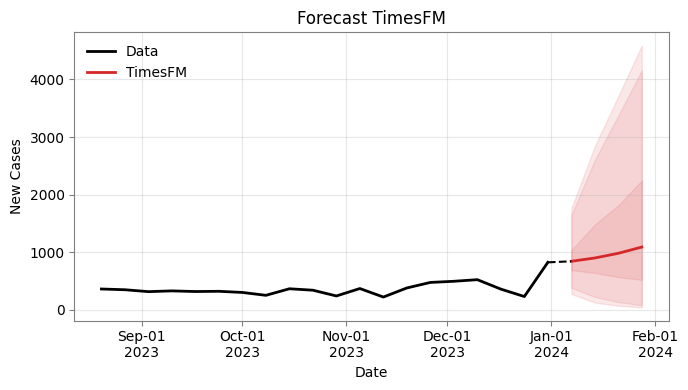

In [23]:
_ ,ax = plot_single_forecast(
    df_for = df_for,
    df_train=df_input.rename(columns = {'data_iniSE': 'date'}),
    last_obs = 20,
    target_col='casos',
    date_col="date",
    conf_levels=[0.5, 0.90, 0.95],
    title="Forecast TimesFM",
    label="TimesFM",
    xlabel="Date",
    ylabel="New Cases",
    figsize=(7, 4))

The code below adds the subsequently observed cases to the figure: 

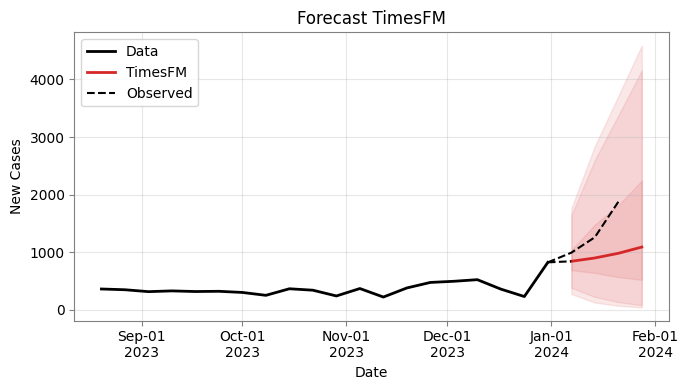

In [24]:
df_obs = df.loc[df.data_iniSE >= '2023-12-31'].iloc[:4]

ax.plot(df_obs.data_iniSE, df_obs.casos, label = 'Observed', linestyle = '--', color = 'black')

ax.legend()

display(ax.figure)